# Session 11 — Auto-Rickshaw Subplots and Advanced Charts

Load the Session 10 `auto_trips.csv` dataset and create a subplot grid, dual-axis chart, area-wise box plots, and an annotated daily-fare chart.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Keep the CSV and notebook in the same folder
df = pd.read_csv("auto_trips.csv", parse_dates=["trip_date"])
print(df.head())
print("Shape:", df.shape)

areas = ["Navrangpura", "Maninagar", "Satellite", "Vastrapur", "Paldi"]
daily_fare = df.set_index("trip_date").resample("D")["fare_inr"].sum()
daily_trips = df.set_index("trip_date").resample("D").size()


   trip_id  trip_date         area  distance_km  fare_inr
0        1 2025-04-03  Navrangpura           10       191
1        2 2025-04-24    Satellite           12       202
2        3 2025-04-20    Satellite           12       223
3        4 2025-04-14    Maninagar            3        88
4        5 2025-04-13  Navrangpura           13       223
Shape: (600, 5)


## 1. Create a 2×2 subplot grid

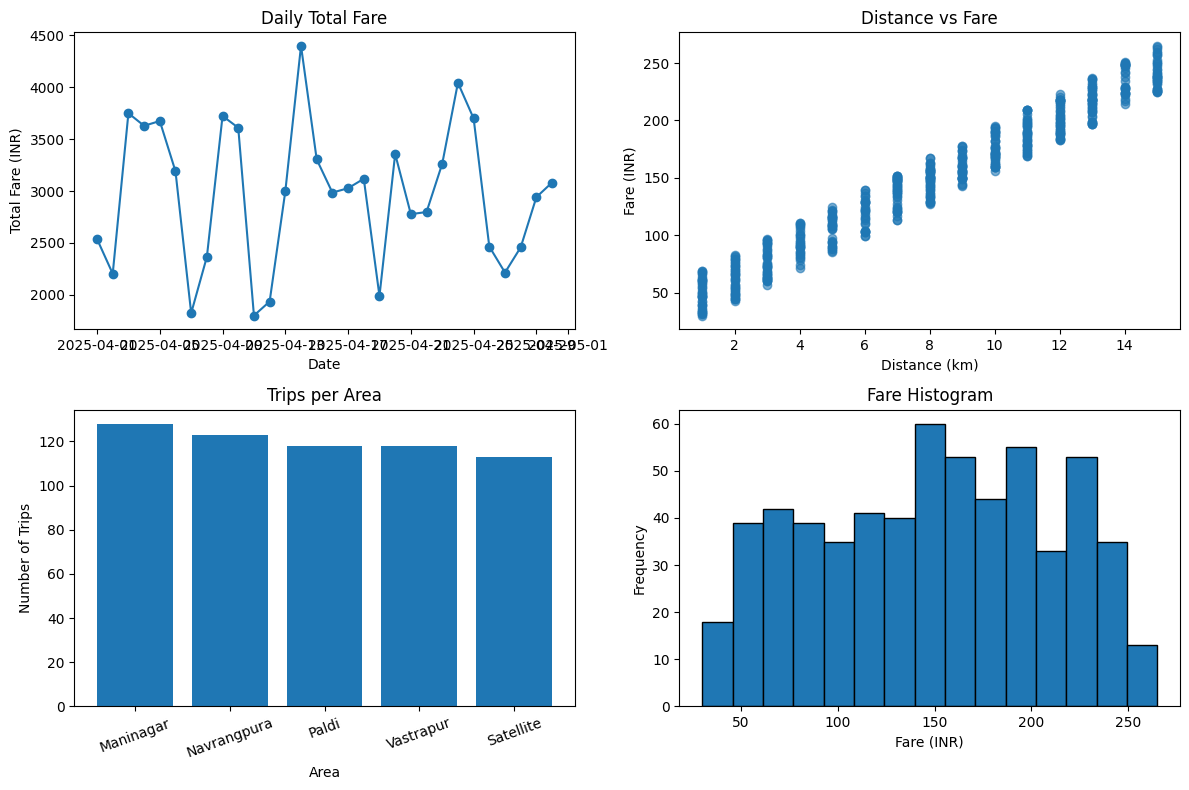

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Daily total fare
axes[0, 0].plot(daily_fare.index, daily_fare.values, marker="o")
axes[0, 0].set_title("Daily Total Fare")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Total Fare (INR)")

# Distance versus fare
axes[0, 1].scatter(df["distance_km"], df["fare_inr"], alpha=0.6)
axes[0, 1].set_title("Distance vs Fare")
axes[0, 1].set_xlabel("Distance (km)")
axes[0, 1].set_ylabel("Fare (INR)")

# Trips per area
area_counts = df["area"].value_counts().sort_values(ascending=False)
axes[1, 0].bar(area_counts.index, area_counts.values)
axes[1, 0].set_title("Trips per Area")
axes[1, 0].set_xlabel("Area")
axes[1, 0].set_ylabel("Number of Trips")
axes[1, 0].tick_params(axis="x", rotation=20)

# Fare histogram
axes[1, 1].hist(df["fare_inr"], bins=15, edgecolor="black")
axes[1, 1].set_title("Fare Histogram")
axes[1, 1].set_xlabel("Fare (INR)")
axes[1, 1].set_ylabel("Frequency")

fig.tight_layout()
fig.savefig("trip_grid.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Dual-axis chart: daily fare and trip count

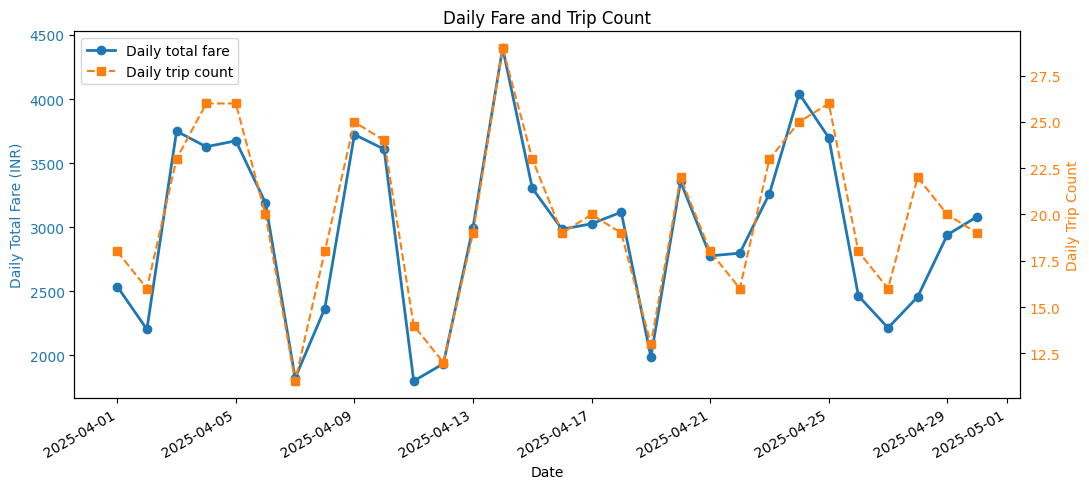

In [3]:
fig, ax1 = plt.subplots(figsize=(11, 5))

line1, = ax1.plot(
    daily_fare.index, daily_fare.values,
    color="tab:blue", linestyle="-", linewidth=2, marker="o",
    label="Daily total fare"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily Total Fare (INR)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
line2, = ax2.plot(
    daily_trips.index, daily_trips.values,
    color="tab:orange", linestyle="--", marker="s",
    label="Daily trip count"
)
ax2.set_ylabel("Daily Trip Count", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

ax1.set_title("Daily Fare and Trip Count")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("fare_vs_trips_dual.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Box plots of fare by area (without groupby or Seaborn)

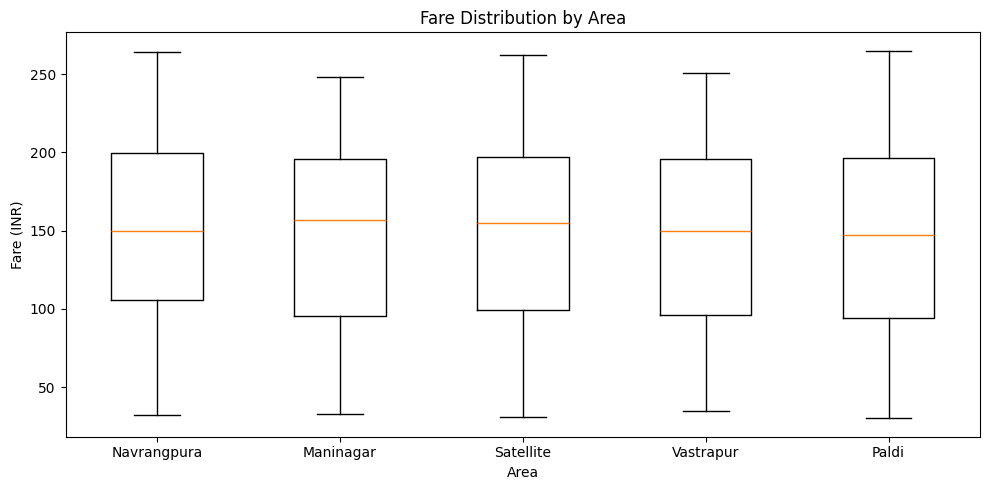

In [4]:
fare_lists = [
    df.loc[df["area"] == area, "fare_inr"].dropna().tolist()
    for area in areas
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(fare_lists)
ax.set_xticklabels(areas)
ax.set_title("Fare Distribution by Area")
ax.set_xlabel("Area")
ax.set_ylabel("Fare (INR)")
fig.tight_layout()
fig.savefig("fare_by_area_box.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Annotate the highest-fare day and verify it

Peak date: 2025-04-14
Peak daily fare: ₹ 4398


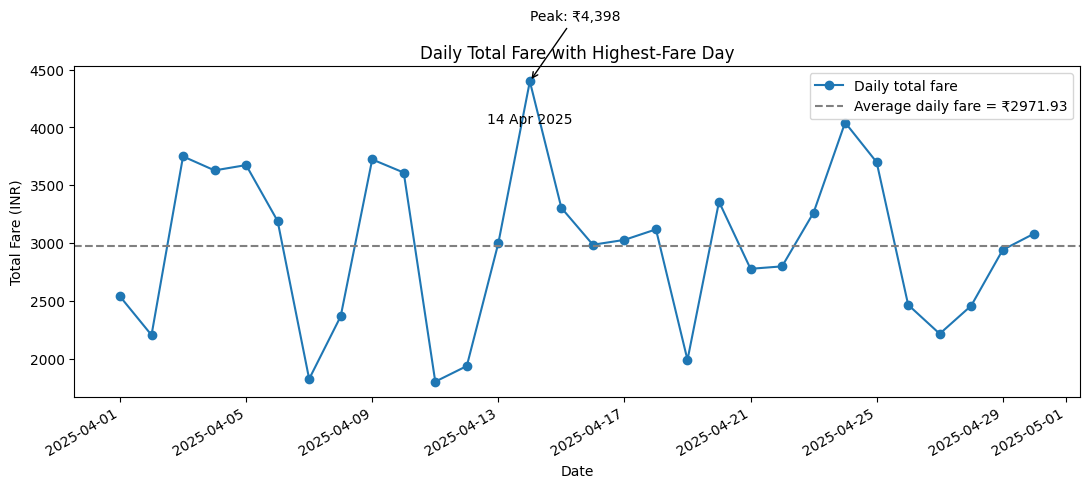

In [5]:
peak_date = daily_fare.idxmax()
peak_fare = daily_fare.max()
average_daily_fare = daily_fare.mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_fare.index, daily_fare.values, marker="o", label="Daily total fare")
ax.axhline(
    average_daily_fare, linestyle="--", color="gray",
    label=f"Average daily fare = ₹{average_daily_fare:.2f}"
)

ax.annotate(
    f"Peak: ₹{peak_fare:,.0f}",
    xy=(peak_date, peak_fare),
    xytext=(peak_date, peak_fare * 1.12),
    arrowprops={"arrowstyle": "->"}
)
ax.text(
    peak_date, peak_fare * 0.94,
    peak_date.strftime("%d %b %Y"),
    ha="center", va="top"
)

ax.set_title("Daily Total Fare with Highest-Fare Day")
ax.set_xlabel("Date")
ax.set_ylabel("Total Fare (INR)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

# Confirm the annotated date is the maximum-fare date
assert peak_date == daily_fare.idxmax()
print("Peak date:", peak_date.date())
print("Peak daily fare: ₹", peak_fare)

fig.savefig("fare_peak_annotated.png", dpi=150, bbox_inches="tight")
plt.show()


## Output check

After running all cells, these four PNG files and the source CSV should be in the notebook folder.

In [6]:
from pathlib import Path

required_files = [
    "trip_grid.png",
    "fare_vs_trips_dual.png",
    "fare_by_area_box.png",
    "fare_peak_annotated.png"
]

for filename in required_files:
    print(filename, "exists:", Path(filename).exists())


trip_grid.png exists: True
fare_vs_trips_dual.png exists: True
fare_by_area_box.png exists: True
fare_peak_annotated.png exists: True
